# 🏢 Anticipez les besoins en consommations de bâtiments (Modélisation)

## 📋 Présentation du Projet
Dans le cadre de son engagement pour la **neutralité carbone d'ici 2050**, la ville de Seattle analyse les données de consommation énergétique de ses bâtiments non résidentiels.

* **Objectif :** Prédire les émissions de CO2 et la consommation totale d'énergie.
* **Cible :** Bâtiments non destinés à l'habitation.

##  1. Imports des modules et du dataset


### Stack Logicielle
| Modules |
| :--- |
| `matplotlib` |
| `pandas` |
| `seaborn` |
| `sickit-learn` |
| `numpy` |
| `category_encoders` |
| `scipy` |

### Source des données
* **Fichier** : `..data/processed/dataset_clean_energy_use.csv`
*  **Format** : CSV

---

##  2. Fonction pour validation de modèle

###  Entrées
Notre fonction va prendre en entrées :
* **Le modèle choisi**
* **Notre dataset sans la variable cible**
* **La variable cible**

### Métriques d'évaluation
* **R2** : pourcentage de réduction de l'erreur par rapport à une estimation basée sur la moyenne
* **MAE** : erreur moyenne absolue
* **RMSE** : Racine carré de l'erreur quadratique
* **Time** : la durée d'entrainement de notre modèle

### Sorties
Retourne le tableau des métriques d'évaluation pour le train et le test.

## 3. Test de différents modèles

### Régression linéaire

| Métrique | R² | MAE | RMSE | Time (sec) |
| :--- | :---: | :---: | :---: | :---: |
| **Train (Fit)** | 0.829045 | 0.384732 | 0.518903 | 0.081300 |
| **Test (Score)** | 0.772017 | 0.434863 | 0.595679 | 0.011957 |

Le modèle obtient des résultats satisfaisants.

### RandomForestRegressor

| Métrique | R² | MAE | RMSE | Time (sec) |
| :--- | :---: | :---: | :---: | :---: |
| **Train (Fit)** | 0.967531 | 0.161669 | 0.226065 | 1.866500 |
| **Test (Score)** | 0.761584 | 0.434039 | 0.607391 | 0.030584 |

On observe de l'overfitting.

### SVR
| Métrique | R² | MAE | RMSE | Time (sec) |
| :--- | :---: | :---: | :---: | :---: |
| **Train (Fit)** | 0.175172 | 0.865014 | 1.139976 | 0.178129 |
| **Test (Score)** | 0.160570 | 0.876621 | 1.145722 | 0.079022 |

Les résultats sont mauvais car pour utiliser ce modèle, il est important de faire de la normalisation.

| Métrique | R² | MAE | RMSE | Time (sec) |
| :--- | :---: | :---: | :---: | :---: |
| **Train (Fit)** | 0.853240 | 0.321099 | 0.480831 | 0.146229 |
| **Test (Score)** | 0.739991 | 0.449386 | 0.637638 | 0.063153 |

Après normalisation, on observe que les résultats deviennent bien meilleurs.

## 4. Optimisation

On utilise la methode GridSearchCV pour tester différentes combinaisons d'hyperparamètres sur un modèle à améliorer.
Post traitement, on arrive à réduire l'overfitting du RandomForestRegressor.

| Métrique | R² | MAE | RMSE | Time (sec) |
| :--- | :---: | :---: | :---: | :---: |
| **Train (Fit)** | 0.881900 | 0.303845 | 0.431246 | 0.677635 |
| **Test (Score)** | 0.755185 | 0.443777 | 0.615662 | 0.024981 |

On peut ensuite utiliser l'attribut **feature_importance** pour mettre en évidence les features ayant le plus d'impact dans la prédiction :
- LogPropertyGFATotal
- LogPropertyGFABuilding(s) 
- LogLargestPropertyUseTypeGFA
- ENERGYSTARScore
- NumberofFloors

## 1. Import des modules et du dataset

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import numpy as np
pd.set_option("display.max_columns", 200)
#Selection
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV, 
    cross_validate,
    KFold
)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, mean_absolute_percentage_error 
from sklearn.inspection import permutation_importance

#Preprocess
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

from sklearn.pipeline import Pipeline

#Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeClassifier


In [33]:
df = pd.read_csv("../data/processed/dataset_clean_energy_use.csv")


## 2. Fonction pour validation de modèle

Détails de la fonction permettant de tester et d'évaluer les modèles :
1. On entre les caractéristiques de notre validation croisée :
    - On divise le jeu en 5 fold
    - On fixe un random_state pour pouvoir obtenir le même aléatoire pour nos différents tests
2. On définit nos métriques d'évaluation :
    * **R2** : pourcentage de réduction de l'erreur par rapport à une estimation basée sur la moyenne
    * **MAE** : erreur moyenne absolue
    * **RMSE** : Racine carré de l'erreur quadratique
    * **Time** : la durée d'entrainement de notre modèle
3. On entraine et teste le modèle selon les paramètres définies précédemment
4. On affiche les métriques d'évaluations du modèle


In [24]:
def modele_validation(modele, X, y):

    cv_details = KFold(n_splits=5, shuffle=True, random_state=42)
    
    scoring = ['r2', 'neg_mean_absolute_error', 'neg_root_mean_squared_error']

    cross_validation_result = cross_validate(modele, X, y, cv=cv_details, scoring=scoring, return_train_score=True)
    
    dict_resultats = {
        "R2": [np.mean(cross_validation_result["train_r2"]), np.mean(cross_validation_result["test_r2"])],
        "MAE": [-np.mean(cross_validation_result["train_neg_mean_absolute_error"]), -np.mean(cross_validation_result["test_neg_mean_absolute_error"])],
        "RMSE": [-np.mean(cross_validation_result["train_neg_root_mean_squared_error"]), -np.mean(cross_validation_result["test_neg_root_mean_squared_error"])],
        "Time (sec)": [np.mean(cross_validation_result["fit_time"]), np.mean(cross_validation_result["score_time"])]
    }
    
    df_visuel = pd.DataFrame(dict_resultats, index=["Train (Fit)", "Test (Score)"])
    display(df_visuel)

In [25]:
# On définit notre variable cible
y = df["LogSiteEnergyUseWN(kBtu)"]

# On créé notre df sans notre variable cible
X = df.drop(columns=["LogSiteEnergyUseWN(kBtu)"])

# Pour interpréter MAE et RMSE, on récupère la moyenne de notre valeur cible
moyenne = df["LogSiteEnergyUseWN(kBtu)"].mean()
print(moyenne)

14.989939950137494


## Test de différents modèles

#### LINEAR REGRESSION

In [26]:
model = LinearRegression()

print("Résultat régression linéaire")
modele_validation(model, X, y)



Résultat régression linéaire


,R2,MAE,RMSE,Time (sec)
Train (Fit),0.828378,0.384998,0.519908,0.131791
Test (Score),0.773661,0.433474,0.593255,0.006249


Interprétation des résultats :
- Le modèle ne fait pas d'overfiting (test_R2 et train_R2 sont proches)
- Le modèle a un temps de fit et predict très rapide
- Si on compare notre MAE à la valeur moyenne de notre colonne cible, on obtient une erreur moyenne de 3%
- Si on compare notre RMSE à la valeur moyenne de notre colonne cible, on obtient une erreur moyenne de 4%

#### RANDOM FOREST REGRESSOR

In [27]:
model = RandomForestRegressor()

print("Résultat RandomForestRegressor")
modele_validation(model, X, y)


Résultat RandomForestRegressor


,R2,MAE,RMSE,Time (sec)
Train (Fit),0.967578,0.161152,0.225965,1.266817
Test (Score),0.766560,0.427811,0.601541,0.026743


Interprétation des résultats :
- Ecart important du R2 entre train et test donc le modèle fait clairement ici de l'overfitting
- La MAE et le RMSE sont acceptables par rapport à la moyenne de la cible
- Time correct

### SVR

In [28]:
model = SVR()
print("Résultat SVR")
modele_validation(model, X, y)

# Normalisation des données
pipeline_svr = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR())
])

print("Résultat SVR avec normalisation")
modele_validation(pipeline_svr, X, y)

Résultat SVR


,R2,MAE,RMSE,Time (sec)
Train (Fit),0.175182,0.865015,1.139969,0.132459
Test (Score),0.160585,0.876620,1.145712,0.050836


Résultat SVR avec normalisation


,R2,MAE,RMSE,Time (sec)
Train (Fit),0.854461,0.319764,0.478814,0.154129
Test (Score),0.748015,0.441452,0.627462,0.056332


Interprétation des résultats :
- Importance de mettre en place une normalisation à l'utilisation de ce modèle
- Léger overfitting
- La MAE et le RMSE sont acceptables par rapport à la moyenne de la cible
- Time correct

### Optimisation d'un modèle

In [29]:
cv_details = KFold(n_splits=5, shuffle=True, random_state=42)

parameters = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, 20, 25, 30, 40, None],
    'min_samples_leaf': [4, 10, 20, 30, 40],
    'max_features': [0.2, 0.4, 0.6, 0.8, 'sqrt']
}
model = RandomForestRegressor()

rfg = GridSearchCV(model, parameters, cv = cv_details, scoring = 'r2', verbose = 1)
rfg.fit(X,y)
display(rfg.best_params_)
display(rfg.best_score_)

Fitting 5 folds for each of 600 candidates, totalling 3000 fits


{'max_depth': 20,
 'max_features': 0.6,
 'min_samples_leaf': 4,
 'n_estimators': 300}

np.float64(0.7581173280493764)

In [30]:
model = RandomForestRegressor(
    max_depth=20,
    max_features=0.4,
    min_samples_leaf=4
)
print("Résultat RandomForestRegressor")
modele_validation(model, X, y)

Résultat RandomForestRegressor


,R2,MAE,RMSE,Time (sec)
Train (Fit),0.882196,0.304023,0.430685,0.408707
Test (Score),0.756400,0.442023,0.614579,0.015926


On récupère le meilleur modèle et on identifie les features ayant le plus d'impact sur la prédiction

In [31]:
best_model = rfg.best_estimator_
importances = best_model.feature_importances_
feature_imp = pd.Series(
    importances, index=X.columns
).sort_values(ascending=False)
display(feature_imp)

LogPropertyGFATotal                    0.428442
LogPropertyGFABuilding(s)              0.196746
LogLargestPropertyUseTypeGFA           0.110526
ENERGYSTARScore                        0.061224
Warehouse                              0.024807
                                         ...   
Prison/Incarceration                   0.000000
Police Station                         0.000000
Strip Mall                             0.000000
Urgent Care/Clinic/Other Outpatient    0.000000
Wholesale Club/Supercenter             0.000000
Length: 95, dtype: float64

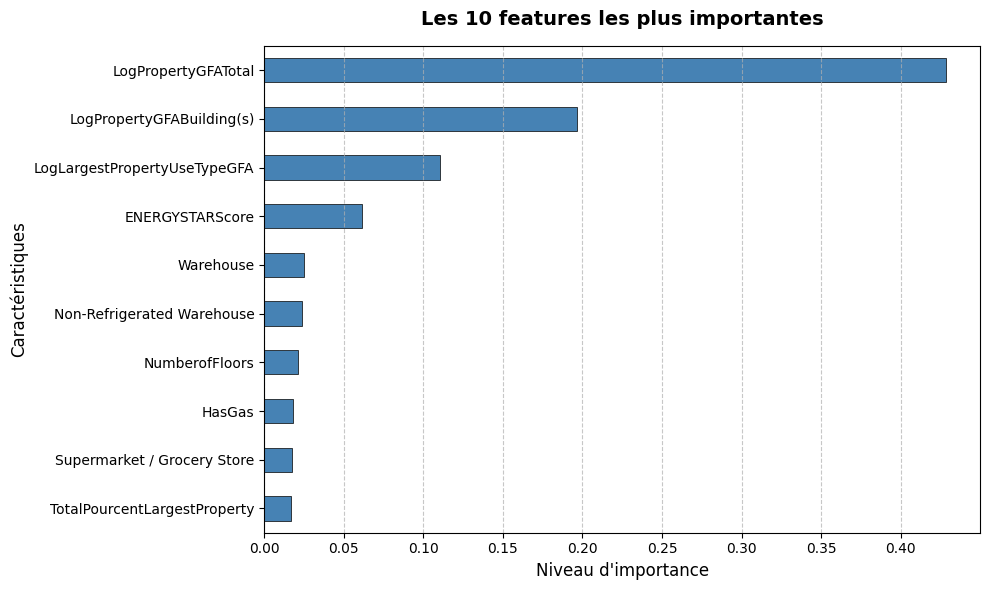

In [32]:
top_10 = feature_imp.head(10)

plt.figure(figsize=(10, 6))

top_10.sort_values(ascending=True).plot(
    kind='barh', 
    color='steelblue', 
    edgecolor='black', 
    linewidth=0.5
)

plt.title("Les 10 features les plus importantes", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Niveau d'importance", fontsize=12)
plt.ylabel("Caractéristiques", fontsize=12)

plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()

plt.show()